In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve
)

import joblib

In [4]:
df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
print("Missing values:", df.isnull().sum().sum())

print("\nClass distribution:")
print(df["Class"].value_counts())

print("\nDataset information:")
df.info()

Missing values: 0

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non

In [11]:
print(df.head())
print(df.columns.tolist())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [12]:
# Separate input features and target variable

X = df.drop('Class', axis=1)
y = df['Class']

print("Features created successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

Features created successfully!
X shape: (284807, 30)
y shape: (284807,)

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training and testing data created!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Training and testing data created!
X_train: (227845, 30)
X_test: (56962, 30)


In [20]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [22]:
rf_pred = rf_model.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [23]:
print("RANDOM FOREST CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    rf_pred,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0
))

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
  Fraudulent       0.84      0.82      0.83        98

    accuracy                           1.00     56962
   macro avg       0.92      0.91      0.91     56962
weighted avg       1.00      1.00      1.00     56962



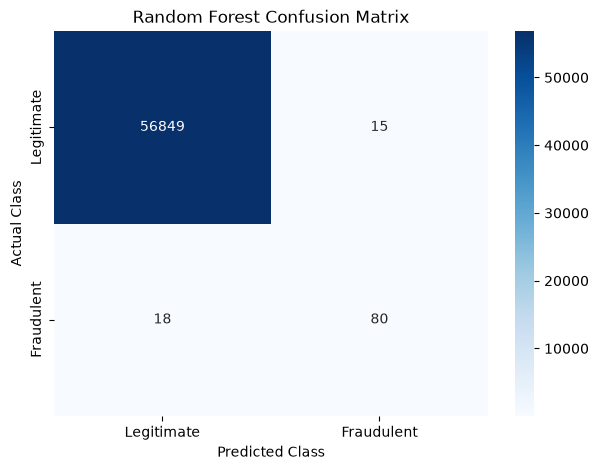

In [24]:
cm_rf = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest Confusion Matrix")

plt.show()

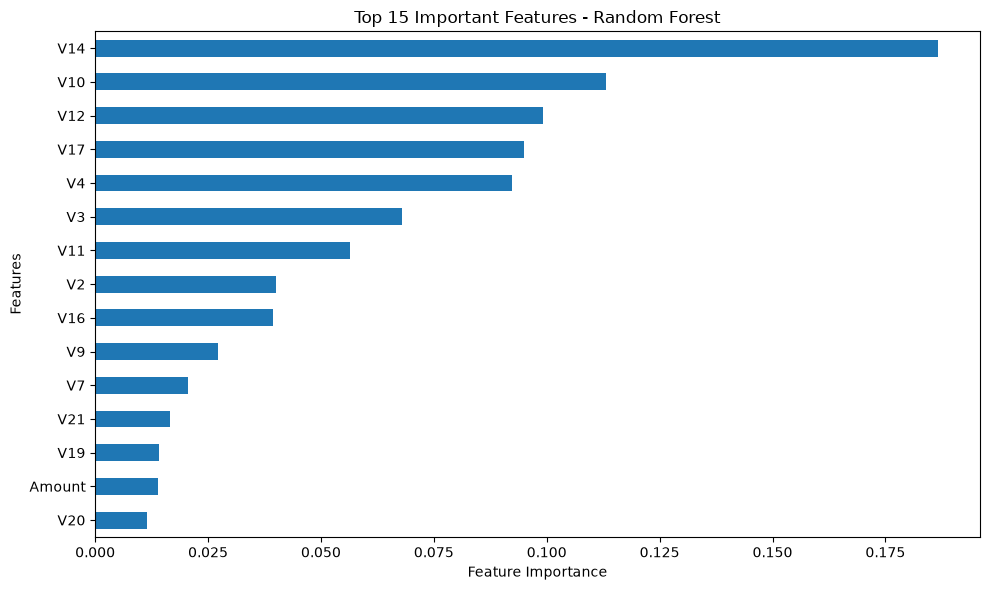

In [25]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
)

importance = importance.sort_values(ascending=False)

plt.figure(figsize=(10, 6))

importance.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [28]:
%whos

Variable                  Type                      Data/Info
-------------------------------------------------------------
ConfusionMatrixDisplay    type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
RandomForestClassifier    ABCMeta                   <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
X                         DataFrame                 Shape: (284807, 30)
X_test                    DataFrame                 Shape: (56962, 30)
X_train                   DataFrame                 Shape: (227845, 30)
average_precision_score   function                  <function average_precisi<...>re at 0x000001804A8DD220>
classification_report     function                  <function classification_<...>rt at 0x000001804A8B2610>
cm_rf                     ndarray                   2x2: 4 elems, type `int64`, 32 bytes
confusion_matrix          function                  <function confusion_matrix at 0x000001804A8B1220>
df                        DataFrame   

In [29]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

model_lr.fit(X_train, y_train)

print("Logistic Regression training completed!")


Logistic Regression training completed!


In [30]:

pred_lr = model_lr.predict(X_test)

rf_pred = rf_model.predict(X_test)

print("Logistic Regression predictions generated!")
print("Random Forest predictions generated!")

print("LR predictions:", len(pred_lr))
print("RF predictions:", len(rf_pred))


Logistic Regression predictions generated!
Random Forest predictions generated!
LR predictions: 56962
RF predictions: 56962


In [31]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

comparison_new = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, pred_lr),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, pred_lr, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, pred_lr, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, pred_lr, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ],
    "Average Precision": [
        average_precision_score(
            y_test, model_lr.predict_proba(X_test)[:, 1]
        ),
        average_precision_score(
            y_test, rf_model.predict_proba(X_test)[:, 1]
        )
    ]
})

display(comparison_new.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,Average Precision
0,Logistic Regression,0.9755,0.0610,0.9184,0.1144,0.7190
1,Random Forest,0.9994,0.8421,0.8163,0.8290,0.8466


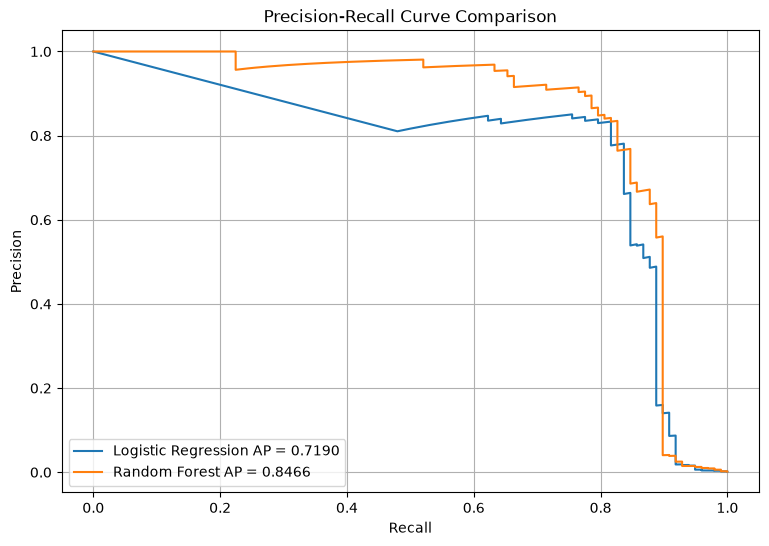

In [33]:

from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Logistic Regression probabilities
lr_probs = model_lr.predict_proba(X_test)[:, 1]

# Random Forest probabilities
rf_probs = rf_model.predict_proba(X_test)[:, 1]

# Calculate curves
lr_precision, lr_recall, _ = precision_recall_curve(y_test, lr_probs)
rf_precision, rf_recall, _ = precision_recall_curve(y_test, rf_probs)

# Calculate Average Precision
lr_ap = average_precision_score(y_test, lr_probs)
rf_ap = average_precision_score(y_test, rf_probs)

# Plot both curves
plt.figure(figsize=(9, 6))

plt.plot(lr_recall, lr_precision,
         label=f"Logistic Regression AP = {lr_ap:.4f}")

plt.plot(rf_recall, rf_precision,
         label=f"Random Forest AP = {rf_ap:.4f}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid()
plt.show()


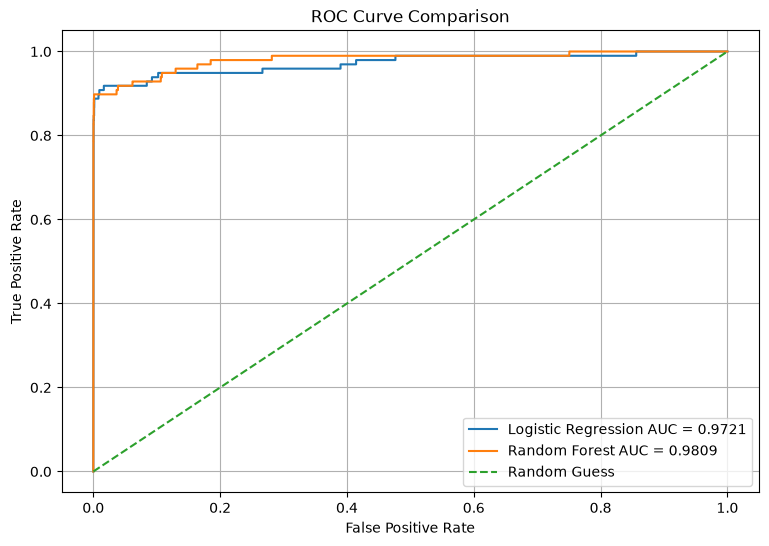

In [34]:

from sklearn.metrics import roc_curve, roc_auc_score

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)

lr_auc = roc_auc_score(y_test, lr_probs)
rf_auc = roc_auc_score(y_test, rf_probs)

plt.figure(figsize=(9, 6))

plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression AUC = {lr_auc:.4f}")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest AUC = {rf_auc:.4f}")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()


In [35]:

import joblib

joblib.dump(rf_model, "credit_fraud_random_forest.pkl")

print("Random Forest model saved successfully!")


Random Forest model saved successfully!


In [36]:
import os

print("Checking saved project files...\n")

for file in os.listdir():
    if file.endswith(".csv") or file.endswith(".pkl"):
        print(file)

Checking saved project files...

creditcard.csv
credit_fraud_random_forest.pkl
Iris.csv


In [37]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import numpy as np

# Get fraud probabilities
fraud_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Thresholds to compare
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results = []

for threshold in thresholds:
    predictions = (fraud_probabilities >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(results)

display(threshold_df.round(4))

# Save as CSV
threshold_df.to_csv("threshold_comparison.csv", index=False)

print("Threshold comparison CSV saved successfully!")

,Threshold,Precision,Recall,F1 Score
0,0.1,0.2643,0.8980,0.4084
1,0.2,0.5686,0.8878,0.6932
2,0.3,0.6829,0.8571,0.7602
3,0.4,0.7714,0.8265,0.7980
4,0.5,0.8421,0.8163,0.8290
5,0.6,0.8652,0.7857,0.8235
6,0.7,0.9136,0.7551,0.8268
7,0.8,0.9155,0.6633,0.7692
8,0.9,0.9667,0.5918,0.7342


Threshold comparison CSV saved successfully!


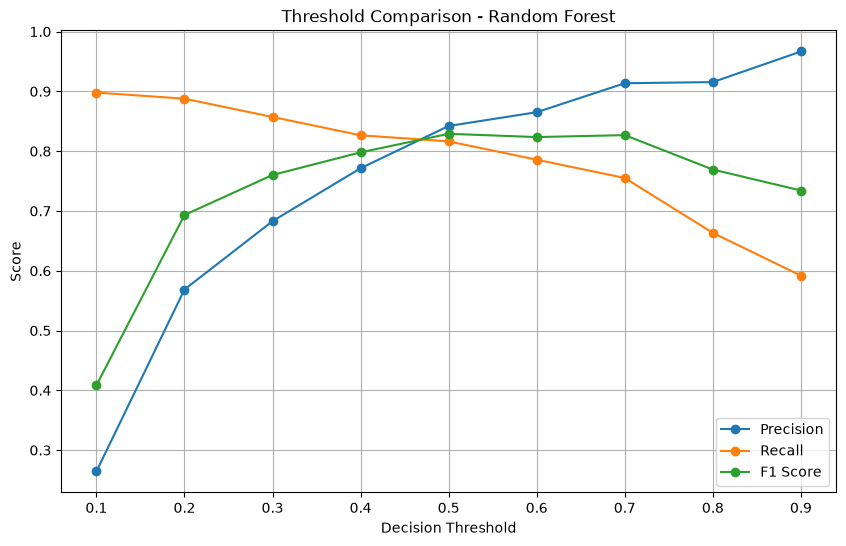

In [38]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Threshold Comparison - Random Forest")
plt.legend()
plt.grid(True)

plt.show()

In [39]:
import os

print(os.path.exists("threshold_comparison.csv"))

True


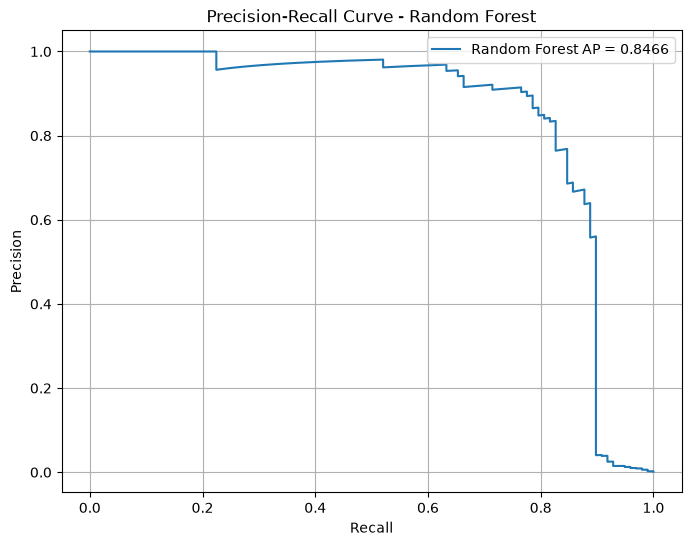

Average Precision: 0.8466


In [40]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate precision and recall
precision, recall, thresholds = precision_recall_curve(
    y_test,
    rf_model.predict_proba(X_test)[:, 1]
)

# Calculate Average Precision
ap_score = average_precision_score(
    y_test,
    rf_model.predict_proba(X_test)[:, 1]
)

# Plot graph
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f"Random Forest AP = {ap_score:.4f}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Random Forest")
plt.legend()
plt.grid(True)
plt.show()

print("Average Precision:", round(ap_score, 4))

In [41]:
import os

os.makedirs("project_graphs", exist_ok=True)

print("Project graphs folder created!")

Project graphs folder created!


In [42]:
plt.savefig(
    "project_graphs/graph_name.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC",
        "Average Precision"
    ],
    "Random Forest": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred),
        recall_score(y_test, rf_pred),
        f1_score(y_test, rf_pred),
        roc_auc_score(
            y_test,
            rf_model.predict_proba(X_test)[:, 1]
        ),
        average_precision_score(
            y_test,
            rf_model.predict_proba(X_test)[:, 1]
        )
    ]
})

display(final_results.round(4))

final_results.to_csv(
    "final_model_results.csv",
    index=False
)

print("Final evaluation results saved!")

,Metric,Random Forest
0,Accuracy,0.9994
1,Precision,0.8421
2,Recall,0.8163
3,F1 Score,0.8290
4,ROC AUC,0.9809
5,Average Precision,0.8466


Final evaluation results saved!


In [44]:
import joblib

joblib.dump(
    rf_model,
    "credit_fraud_random_forest.pkl"
)

threshold_df.to_csv(
    "threshold_comparison.csv",
    index=False
)

print("All important project files saved!")

All important project files saved!


In [45]:
joblib.dump(
    list(X_train.columns),
    "model_features.pkl"
)

print("Model features saved!")

Model features saved!


In [51]:
import os

print("Random Forest model:", os.path.exists("credit_fraud_random_forest.pkl"))
print("Feature names:", os.path.exists("model_features.pkl"))

Random Forest model: True
Feature names: True


In [52]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

st.title("Credit Card Fraud Detection System")

model = joblib.load("credit_fraud_random_forest.pkl")
features = joblib.load("model_features.pkl")

st.write("Upload your transaction dataset to detect possible fraud.")

uploaded_file = st.file_uploader("Upload CSV", type=["csv"])

if uploaded_file:
    data = pd.read_csv(uploaded_file)

    missing = [c for c in features if c not in data.columns]

    if missing:
        st.error(f"Missing columns: {missing}")
    else:
        probabilities = model.predict_proba(data[features])[:, 1]

        data["Fraud Probability"] = probabilities
        data["Prediction"] = [
            "Fraudulent" if p >= 0.5 else "Legitimate"
            for p in probabilities
        ]

        st.dataframe(data)

        st.metric("Potential Fraud Cases",
                  int((probabilities >= 0.5).sum()))

        st.download_button(
            "Download Results",
            data.to_csv(index=False),
            "fraud_predictions.csv"
        )

Overwriting app.py


In [54]:
# Create a valid test dataset
test_valid = df.head(100).copy()

# Create a dataset with missing values
test_missing = test_valid.copy()
test_missing.loc[0, "Amount"] = np.nan

# Create a dataset with incorrect text values
test_wrong = test_valid.copy()

# Convert Amount column to object type
test_wrong["Amount"] = test_wrong["Amount"].astype(object)

# Insert invalid text
test_wrong.loc[0, "Amount"] = "invalid"

# Save test datasets
test_valid.to_csv("test_valid.csv", index=False)
test_missing.to_csv("test_missing.csv", index=False)
test_wrong.to_csv("test_wrong_values.csv", index=False)

print("All three test datasets created successfully!")

All three test datasets created successfully!


In [56]:
test_wrong = pd.read_csv("creditcard.csv").head(10).copy()

test_wrong["Amount"] = test_wrong["Amount"].astype(object)
test_wrong.loc[0, "Amount"] = "invalid"

test_wrong.to_csv("test_wrong_values.csv", index=False)

print("Invalid-value test dataset created!")

Invalid-value test dataset created!
